In [6]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, log_expit
from scipy.stats import norm, t
import matplotlib.pyplot as plt

In [7]:
def lse2(a, b):
    """log(exp(a) + exp(b))"""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    m = np.maximum(a, b)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = m + np.log(np.exp(a - m) + np.exp(b - m))
    return np.where(np.isinf(m), m, out)

def lnorm(l, dx):
    """Normalise log-density on a uniform grid."""
    return l - np.log(np.sum(np.exp(l)) * dx)

def log_w(l, lref):
    """log[ e^l / (e^l + e^lref) ]"""
    with np.errstate(invalid="ignore"):
        x = np.asarray(l - lref, dtype=float)
    x = np.where(np.isnan(x), 0.0, x)  # both -Inf -> w = 0.5
    return log_expit(x)

def div_metrics(lp, lq, dx):
    """Inputs: normalised log-densities."""
    p = np.exp(lp)
    q = np.exp(lq)
    # Handle 0 * (-inf) safely where p or q underflows to 0
    kl = np.sum(np.where(p > 0, p * (lp - lq), 0.0)) * dx
    rkl = np.sum(np.where(q > 0, q * (lq - lp), 0.0)) * dx
    tv = 0.5 * np.sum(np.abs(p - q)) * dx
    return {"KL": kl, "RKL": rkl, "TV": tv}

In [8]:
def log_target(theta):
    theta = np.asarray(theta, dtype=float)
    l1 = (np.log(0.8) + np.log(2) + 
          t.logpdf(theta + 5, df=3) + 
          t.logcdf(-4 * (theta + 5), df=3))
    l2 = (np.log(0.2) + np.log(2) + 
          t.logpdf(theta - 5, df=3) + 
          t.logcdf(5 * (theta - 5), df=3))
    return lse2(l1, l2)

def nlt(th):
    return float(-log_target(np.asarray(th).item()))

def exact_nlt_derivs(theta, nu=3.0):
    def comp_derivs(x, alpha, log_w):
        # Log-density value
        l = log_w + np.log(2.0) + t.logpdf(x, df=nu) + t.logcdf(alpha * x, df=nu)
        
        # 1st and 2nd derivatives of log(t_pdf)
        d1_lpdf = -(nu + 1.0) * x / (nu + x**2)
        d2_lpdf = -(nu + 1.0) * (nu - x**2) / (nu + x**2)**2
        
        # 1st and 2nd derivatives of log(t_cdf(alpha * x))
        z = alpha * x
        r = np.exp(t.logpdf(z, df=nu) - t.logcdf(z, df=nu))
        d1_lpdf_z = -(nu + 1.0) * z / (nu + z**2)
        
        d1_lcdf = alpha * r
        d2_lcdf = (alpha**2) * r * (d1_lpdf_z - r)
        
        return l, d1_lpdf + d1_lcdf, d2_lpdf + d2_lcdf

    l1, d1_1, d2_1 = comp_derivs(theta + 5.0, -4.0, np.log(0.8))
    l2, d1_2, d2_2 = comp_derivs(theta - 5.0,  5.0, np.log(0.2))

    w1 = expit(l1 - l2)
    w2 = 1.0 - w1

    # Negate to get derivatives of nlt(theta) = -log_target(theta)
    grad = -(w1 * d1_1 + w2 * d1_2)
    hess = -(w1 * d2_1 + w2 * d2_2 + w1 * w2 * (d1_1 - d1_2)**2)
    return grad, hess

In [9]:
# Multi-start BFGS
opt1 = minimize(lambda th: nlt(th[0]), x0=[-10.0], method="BFGS",
                jac=lambda th: np.array([exact_nlt_derivs(th[0])[0]]),
                options={"gtol": 1e-12})
opt2 = minimize(lambda th: nlt(th[0]), x0=[20.0], method="BFGS",
                jac=lambda th: np.array([exact_nlt_derivs(th[0])[0]]),
                options={"gtol": 1e-12})

mu = np.array([opt1.x[0], opt2.x[0]])
H  = np.array([exact_nlt_derivs(mu[0])[1], exact_nlt_derivs(mu[1])[1]])
sdv = 1.0 / np.sqrt(H)

In [10]:
# Results
print("Start at x0=-10")
print(opt1)
print("Start at x0=10")
print(opt2)

Start at x0=-10
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.7444525377939114
        x: [-5.392e+00]
      nit: 5
      jac: [-5.361e-13]
 hess_inv: [[ 2.719e-01]]
     nfev: 12
     njev: 12
Start at x0=10
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 2.0904196723648893
        x: [ 5.361e+00]
      nit: 7
      jac: [ 1.201e-15]
 hess_inv: [[ 2.472e-01]]
     nfev: 19
     njev: 19


In [11]:
mu, H

(array([-5.3920896 ,  5.36099503]), array([3.67765908, 4.04520778]))

In [12]:
# Compute the mixture weights
logZ = log_target(mu) + 0.5 * np.log(2.0 * np.pi / H)
lam = np.exp(logZ - np.max(logZ))
lam = lam / np.sum(lam)
print(lam)

[0.8011656 0.1988344]


In [13]:
# Partition of unity r_k (fixed Gaussian Laplace mixture)
def logr(th, k):
    a0 = np.log(lam[0]) + norm.logpdf(th, loc=mu[0], scale=sdv[0])
    a1 = np.log(lam[1]) + norm.logpdf(th, loc=mu[1], scale=sdv[1])
    ak = a0 if k == 0 else a1
    return ak - lse2(a0, a1)

In [14]:
# Models
def make_models(base="gauss", nu=3):
    def lbk(th, k):
        if base == "gauss":
            return norm.logpdf(th, loc=mu[k], scale=sdv[k])
        else:
            s = sdv[k] * np.sqrt((nu + 1) / nu)
            return t.logpdf((th - mu[k]) / s, df=nu) - np.log(s)

    def lb_mix(th):
        return lse2(np.log(lam[0]) + lbk(th, 0), np.log(lam[1]) + lbk(th, 1))

    ts = np.mean(mu)  # global reflection point

    def lbar_B(th):
        return np.log(0.5) + lse2(lb_mix(th), lb_mix(2 * ts - th))

    def loc(th, k):
        return log_target(th) + logr(th, k)  # log(pi * r_k), unnormalised

    def skew_comp(th, k, local):
        refl = 2 * mu[k] - th
        if local:
            l, lr = loc(th, k), loc(refl, k)
        else:
            l, lr = log_target(th), log_target(refl)
        return np.log(2) + lbk(th, k) + log_w(l, lr)

    def mix2(a, b, wt):
        return lse2(np.log(wt[0]) + a, np.log(wt[1]) + b)

    models = {
        "Base": lb_mix,
        # "A_naive": lambda th: mix2(skew_comp(th, 0, False), skew_comp(th, 1, False), lam),
        "B_global": lambda th: np.log(2) + lbar_B(th) + log_w(log_target(th), log_target(2 * ts - th)),
        "C_laplaceW": lambda th: mix2(skew_comp(th, 0, True), skew_comp(th, 1, True), lam),
    }
    return {"models": models, "lbk": lbk, "lbar_B": lbar_B, "loc": loc, "ts": ts}

In [15]:
# Divergences on a grid
def evaluate(base, nu=3, L=60.0, dx=0.005):
    g = np.arange(-L, L + 1e-12, dx)
    mod = make_models(base, nu)["models"]
    lp = lnorm(log_target(g), dx)
    rows = {}
    for name, f in mod.items():
        lq = f(g)
        metrics = div_metrics(lp, lnorm(lq, dx), dx)
        rows[name] = {"mass": np.sum(np.exp(lq)) * dx, **metrics}
    return pd.DataFrame.from_dict(rows, orient="index")

pd.set_option("display.precision", 4)
print("===== Results: Gaussian base =====")
print(evaluate("gauss"))
print("\n===== Results: Student-t base (nu = 3) =====")
print(evaluate("t", 3))

===== Results: Gaussian base =====
            mass      KL     RKL      TV
Base         1.0  3.1104  0.3147  0.2733
B_global     1.0  3.0609  0.3122  0.2732
C_laplaceW   1.0  2.9043  0.2005  0.2161

===== Results: Student-t base (nu = 3) =====
            mass      KL     RKL      TV
Base         1.0  0.2409  0.3577  0.2125
B_global     1.0  0.2396  0.3526  0.2125
C_laplaceW   1.0  0.0357  0.0284  0.0762


In [16]:
def check_identity(center, lpi_fun, lqbar_fun, label, L=60.0, dx=0.005):
    g = center + np.arange(-L, L + 1e-12, dx)
    lpi = lnorm(lpi_fun(g), dx)
    lqb = lnorm(lqbar_fun(g), dx)
    lq = np.log(2) + lqb + log_w(lpi, lpi[::-1])
    lpib = lse2(lpi, lpi[::-1]) - np.log(2)

    res = pd.DataFrame.from_dict({
        "D[pi||q_skew]":  div_metrics(lpi,  lq,  dx),
        "D[pibar||qbar]": div_metrics(lpib, lqb, dx),
        "D[pi||qbar]":    div_metrics(lpi,  lqb, dx),
    }, orient="index")
    print(f"\n-- {label} --")
    print(res.round(5))

for b in ["gauss", "t"]:
    M = make_models(b, 3)
    check_identity(M["ts"], log_target, M["lbar_B"], f"B_global, {b}")
    for k in range(2):
        check_identity(
            mu[k],
            lambda g, k=k, M=M: M["loc"](g, k),
            lambda g, k=k, M=M: M["lbk"](g, k),
            f"C component {k+1}, {b}"
        )


-- B_global, gauss --
                    KL     RKL      TV
D[pi||q_skew]   3.0609  0.3122  0.2732
D[pibar||qbar]  3.0609  0.3122  0.2732
D[pi||qbar]     3.2547  0.5611  0.3788

-- C component 1, gauss --
                    KL     RKL      TV
D[pi||q_skew]   2.8397  0.1956  0.2123
D[pibar||qbar]  2.8397  0.1956  0.2123
D[pi||qbar]     3.0379  0.3001  0.2680

-- C component 2, gauss --
                    KL     RKL      TV
D[pi||q_skew]   3.2616  0.2202  0.2315
D[pibar||qbar]  3.2616  0.2202  0.2315
D[pi||qbar]     3.4994  0.3737  0.2941

-- B_global, t --
                    KL     RKL      TV
D[pi||q_skew]   0.2396  0.3526  0.2125
D[pibar||qbar]  0.2396  0.3526  0.2125
D[pi||qbar]     0.4334  0.6176  0.3791

-- C component 1, t --
                    KL     RKL      TV
D[pi||q_skew]   0.0327  0.0261  0.0724
D[pibar||qbar]  0.0327  0.0261  0.0724
D[pi||qbar]     0.2308  0.4839  0.2073

-- C component 2, t --
                    KL     RKL      TV
D[pi||q_skew]   0.0476  0.0374  0.0

In [17]:
# Sensitivity checks
print("\n===== Grid-range sensitivity (KL and TV) =====")
for b in ["gauss", "t"]:
    for L in [30, 60, 120]:
        r = evaluate(b, L=L)
        print(f"{b:<5} L={L:3d} | Base KL={r.loc['Base', 'KL']:.4f} TV={r.loc['Base', 'TV']:.4f} | "
              f"C_laplaceW KL={r.loc['C_laplaceW', 'KL']:.4f} TV={r.loc['C_laplaceW', 'TV']:.4f}")

print("\n===== Degrees-of-freedom sweep (t base) =====")
sweep_rows = []
for nu in [2, 3, 5, 10, 30]:
    r = evaluate("t", nu)
    for method in ["Base", "B_global", "C_laplaceW"]:
        sweep_rows.append({
            "nu": nu,
            "method": method,
            "KL": r.loc[method, "KL"],
            "RKL": r.loc[method, "RKL"],
            "TV": r.loc[method, "TV"]
        })

sweep = pd.DataFrame(sweep_rows)
print(sweep.to_string(index=False))


===== Grid-range sensitivity (KL and TV) =====
gauss L= 30 | Base KL=2.8491 TV=0.2732 | C_laplaceW KL=2.6431 TV=0.2160
gauss L= 60 | Base KL=3.1104 TV=0.2733 | C_laplaceW KL=2.9043 TV=0.2161
gauss L=120 | Base KL=3.2266 TV=0.2733 | C_laplaceW KL=3.0205 TV=0.2161
t     L= 30 | Base KL=0.2408 TV=0.2125 | C_laplaceW KL=0.0356 TV=0.0761
t     L= 60 | Base KL=0.2409 TV=0.2125 | C_laplaceW KL=0.0357 TV=0.0762
t     L=120 | Base KL=0.2409 TV=0.2125 | C_laplaceW KL=0.0357 TV=0.0762

===== Degrees-of-freedom sweep (t base) =====
 nu     method     KL    RKL     TV
  2       Base 0.2086 0.4596 0.2160
  2   B_global 0.2075 0.4523 0.2159
  2 C_laplaceW 0.0054 0.0057 0.0420
  3       Base 0.2409 0.3577 0.2125
  3   B_global 0.2396 0.3526 0.2125
  3 C_laplaceW 0.0357 0.0284 0.0762
  5       Base 0.3525 0.3094 0.2306
  5   B_global 0.3509 0.3054 0.2306
  5 C_laplaceW 0.1466 0.0791 0.1288
 10       Base 0.6055 0.3004 0.2498
 10   B_global 0.6030 0.2971 0.2497
 10 C_laplaceW 0.3994 0.1340 0.1712
 30  

In [22]:
def plot_model_densities(base="t", nu=3, xlim=(-15, 15), dx=0.005):
    g = np.arange(xlim[0], xlim[1] + 1e-12, dx)
    M = make_models(base=base, nu=nu)
    models = M["models"]
    pi_vals = np.exp(log_target(g))

    qbar_funs = {
        "Base":       models["Base"],
        "B_global":   M["lbar_B"],
        "C_laplaceW": models["Base"],
    }
    titles = {
        "Base":       "Base (Symmetric Mixture)",
        "B_global":   "B_global (Global Reflection at $t_s$)",
        "C_laplaceW": "C_laplaceW (Localized Partition)",
    }

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

    for ax, name in zip(axes, ["Base", "B_global", "C_laplaceW"]):
        q_vals = np.exp(models[name](g))
        qbar_vals = np.exp(qbar_funs[name](g))

        ax.plot(g, pi_vals, color="black", lw=2.2, label=r"True $\pi(\theta)$")
        if name == "Base":
            ax.plot(g, qbar_vals, color="#1f77b4", ls="--", lw=1.8,
                    label=r"$\bar{q}(\theta) = q(\theta)$")
        else:
            ax.plot(g, qbar_vals, color="#7f7f7f", ls="--", lw=1.6,
                    label=r"Symmetric $\bar{q}(\theta)$")
            ax.plot(g, q_vals, color="#d62728", lw=2.0,
                    label=r"Skewed $q(\theta)$")

        for k in range(2):
            ax.axvline(mu[k], color="gray", ls=":", lw=1.0, alpha=0.7)
        if name == "B_global":
            ax.axvline(M["ts"], color="#2ca02c", ls="-.", lw=1.2, alpha=0.8,
                       label=r"Midpoint $t_s$")

        ax.set_title(titles[name], fontsize=11, fontweight="bold")
        ax.set_xlabel(r"$\theta$", fontsize=11)
        ax.grid(True, alpha=0.25)
        ax.legend(loc="upper right", fontsize=8.5, frameon=True)

    axes[0].set_ylabel("Density", fontsize=11)
    base_label = "Gaussian Base" if base == "gauss" else rf"Student-$t$ Base ($\nu = {nu}$)"
    fig.suptitle(rf"Target $\pi(\theta)$, Base $\bar{{q}}(\theta)$, and Approximation $q(\theta)$ — {base_label}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

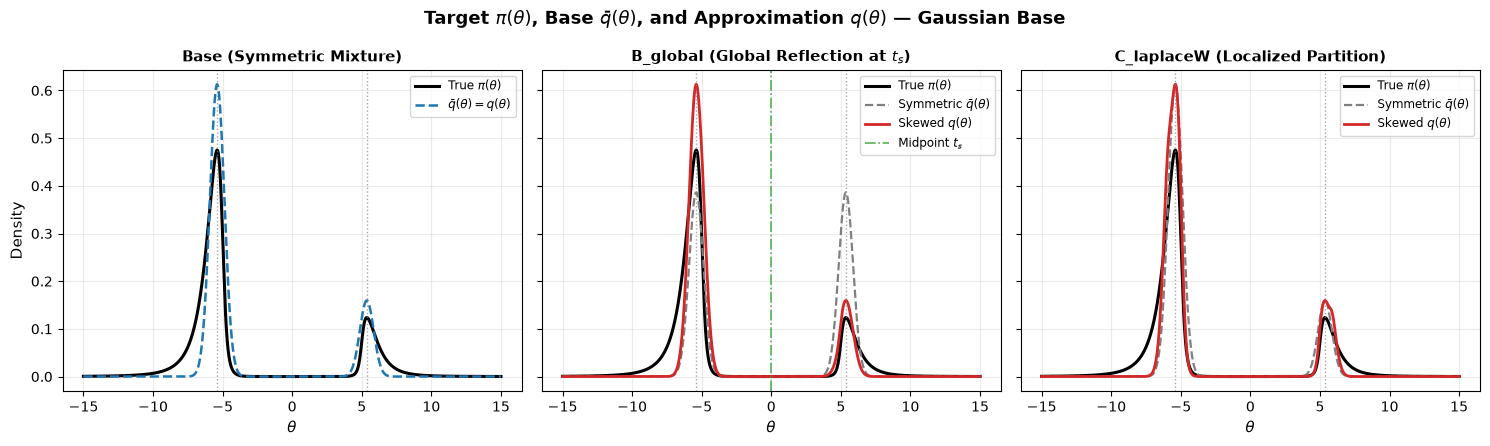

In [23]:
# Generate plots for both bases
plot_model_densities(base="gauss", xlim=(-15, 15))

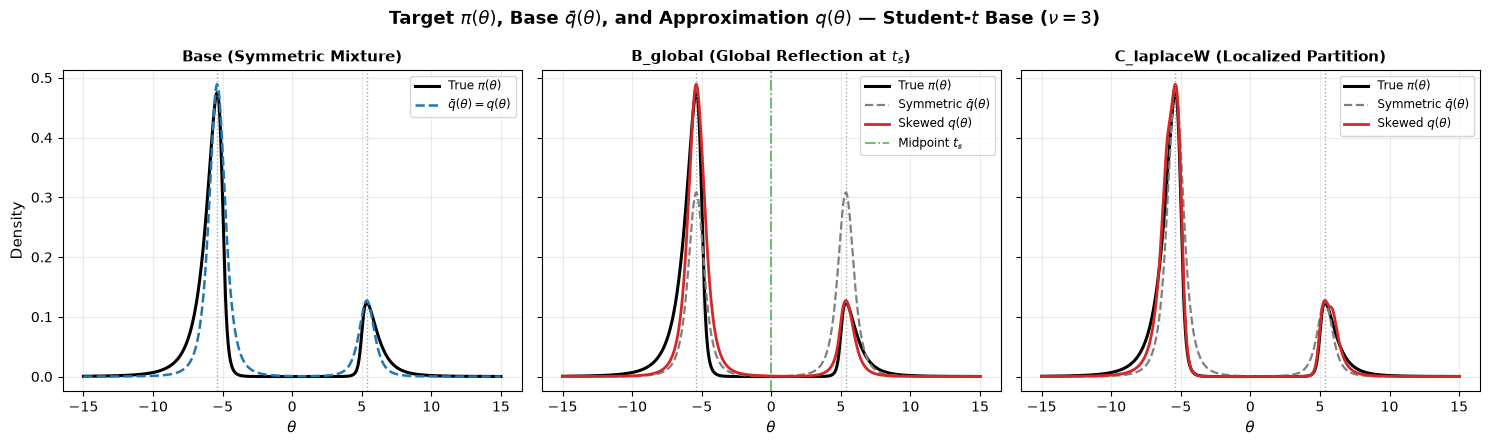

In [24]:
plot_model_densities(base="t", nu=3, xlim=(-15, 15))